# Myopic policy dispatcher run

This notebook runs the checked-in myopic-policy dispatch config through the repo-owned dispatcher, writes the Zarr result store under `artifacts/notebook_runs/`, and then reads the generated files back.

## Imports

In [1]:
import json
import sys
import tempfile
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from dask.distributed import Client, LocalCluster

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from tasks.dispatch.dispatcher import dispatch_from_config
from tasks.policies import load_policy_results

## Start a local Dask cluster

In [2]:
n_workers = 4
threads_per_worker = 1

cluster = LocalCluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    processes=False,
    dashboard_address=None,
)
client = Client(cluster)

{
    "scheduler_address": cluster.scheduler_address,
    "dashboard_link": client.dashboard_link,
    "n_workers": len(client.scheduler_info()["workers"]),
    "threads_per_worker": threads_per_worker,
}


{'scheduler_address': 'inproc://134.214.19.74/50202/1',
 'dashboard_link': 'http://134.214.19.74:8787/status',
 'n_workers': 4,
 'threads_per_worker': 1}

## Load the checked-in config and prepare runtime settings

In [3]:
source_config_path = project_root / "configs" / "myopic_policy" / "baseline.dispatch_config.json"
source_config = json.loads(source_config_path.read_text(encoding="utf-8"))

started_slug = datetime.now().astimezone().strftime("%Y%m%dT%H%M%S")
run_dir = project_root / "artifacts" / "notebook_runs" / f"myopic-policy-{started_slug}"
run_dir.mkdir(parents=True, exist_ok=False)

runtime_config = dict(source_config)
runtime_config["scheduler_address"] = cluster.scheduler_address
runtime_config["output_dir"] = str(run_dir)

{
    "source_config_path": str(source_config_path),
    "run_dir": str(run_dir),
    "scheduler_address": runtime_config["scheduler_address"],
    "output_dir": runtime_config["output_dir"],
    "write_batch_size": runtime_config["write_batch_size"],
}


{'source_config_path': '/home/hdahmou/Network_creation/configs/myopic_policy/baseline.dispatch_config.json',
 'run_dir': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228',
 'scheduler_address': 'inproc://134.214.19.74/50202/1',
 'output_dir': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228',
 'write_batch_size': 32}

## Dispatch the task

In [4]:
with tempfile.NamedTemporaryFile(
    mode="w",
    suffix=".dispatch_config.json",
    encoding="utf-8",
    delete=False,
) as handle:
    json.dump(runtime_config, handle, indent=2)
    handle.write("\n")
    temp_config_path = Path(handle.name)

try:
    dispatch_summary = dispatch_from_config(str(temp_config_path))
finally:
    temp_config_path.unlink(missing_ok=True)

dispatch_summary


INFO Preparing task myopic-policy (tasks.policies.myopic:MyopicPolicyRun)
INFO Initialized output /home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228/myopic-policy-20260406T001229.zarr
INFO Connected to scheduler inproc://134.214.19.74/50202/1
INFO Run finished for myopic-policy: 16 successes, 0 failures


{'success_count': 16,
 'failure_count': 0,
 'task_name': 'myopic-policy',
 'started_at': '20260406T001229',
 'task_class': 'tasks.policies.myopic:MyopicPolicyRun',
 'success_rows_written': 16,
 'failure_rows_written': 0,
 'output_zarr': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228/myopic-policy-20260406T001229.zarr',
 'config_copy_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228/myopic-policy-20260406T001229.dispatch_config.json'}

## Load formatted policy results

In [5]:
result_store_path = Path(dispatch_summary["output_zarr"])
policy_results = load_policy_results(result_store_path)
input_index = policy_results.metadata["input_index"]
parameter_values = policy_results.inputs["tensors"]["parameters"]
output_tensors = policy_results.outputs["tensors"]
output_labels = policy_results.outputs["labels"]

{
    "result_store_path": str(policy_results.metadata["result_store_path"]),
    "task_name": policy_results.metadata["task_name"],
    "task_class": policy_results.metadata["task_class"],
    "average_completion_duration_ms": policy_results.metadata["average_completion_duration_ms"],
    "stored_results": int(input_index.shape[0]),
    "stored_failures": int(policy_results.failures["error"].shape[0]) if "error" in policy_results.failures else 0,
    "parameters_shape": tuple(parameter_values.shape),
    "output_tensors": {name: tuple(values.shape) for name, values in output_tensors.items()},
    "run_dir_files": sorted(path.name for path in run_dir.iterdir()),
}


{'result_store_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/myopic-policy-20260406T001228/myopic-policy-20260406T001229.zarr',
 'task_name': 'myopic-policy',
 'task_class': 'tasks.policies.myopic:MyopicPolicyRun',
 'average_completion_duration_ms': 105106.33969001174,
 'stored_results': 16,
 'stored_failures': 0,
 'parameters_shape': (16, 5),
 'output_tensors': {'timeseries': (16, 2, 361), 'final': (16, 2)},
 'run_dir_files': ['myopic-policy-20260406T001229.dispatch_config.json',
  'myopic-policy-20260406T001229.zarr']}

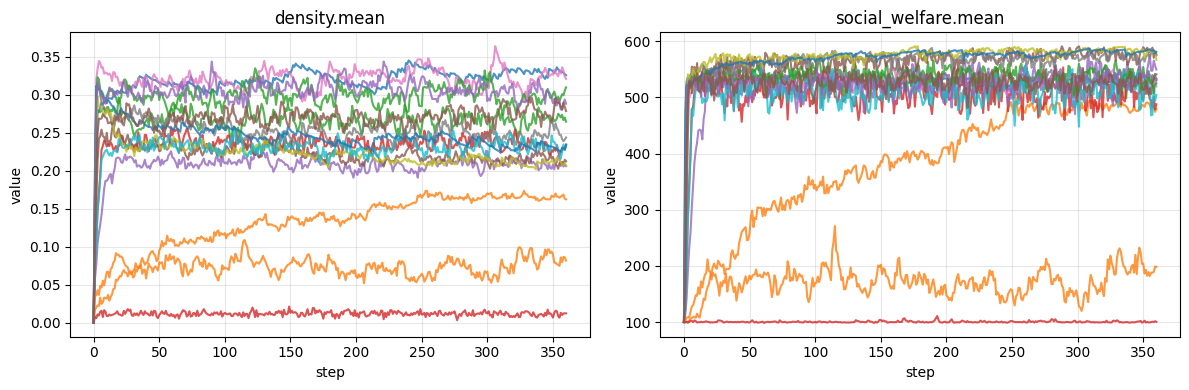

In [6]:
timeseries = output_tensors["timeseries"]
observables = output_labels["observable"]
steps = output_labels["step"]

fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
axes = np.atleast_1d(axes)
for observable_index, observable_name in enumerate(observables):
    for row_index, sample_idx in enumerate(input_index):
        axes[observable_index].plot(
            steps,
            timeseries[row_index, observable_index],
            alpha=0.8,
            label=f"sample {int(sample_idx)}",
        )
    axes[observable_index].set_title(str(observable_name))
    axes[observable_index].set_xlabel("step")
    axes[observable_index].set_ylabel("value")
    axes[observable_index].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:
summary = {"sample": input_index}
for parameter_index, parameter_name in enumerate(policy_results.inputs["labels"]["parameter"]):
    summary[f"parameter.{parameter_name}"] = parameter_values[:, parameter_index]

for observable_index, observable_name in enumerate(observables):
    summary[f"{observable_name}.final"] = output_tensors["final"][:, observable_index]

summary


{'sample': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15]),
 'parameter.link_cost': array([20., 20., 20., 20., 20., 20., 20., 20., 20., 20., 20., 20., 20.,
        20., 20., 20.], dtype=float32),
 'parameter.decay': array([0.36899152, 0.8837106 , 0.5628856 , 0.26809195, 0.6925522 ,
        0.76841444, 0.22142816, 0.6717891 , 0.9691928 , 0.55649304,
        0.83952636, 0.09079706, 0.49962255, 0.38243854, 0.05485603,
        0.16920257], dtype=float32),
 'parameter.per_link_benefit': array([10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
        10., 10., 10.], dtype=float32),
 'parameter.bridge_probability': array([0.96206415, 0.08793566, 0.53020257, 0.31463167, 0.23485704,
        0.40406016, 0.8626205 , 0.7566239 , 0.6049491 , 0.30439904,
        0.9186935 , 0.13075617, 0.6884855 , 0.04645301, 0.67636484,
        0.47691104], dtype=float32),
 'parameter.radius': array([10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
        10.

## Cleanup

In [8]:
client.close()
cluster.close()
